In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/shows.csv")
df.shape

(3000, 15)

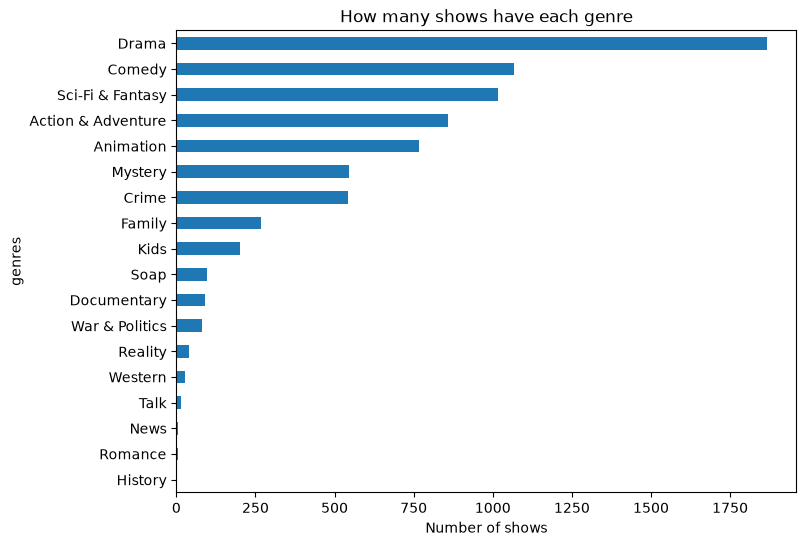

In [3]:
# Each show can have several genres in one cell, e.g. "Drama|Comedy".
genre_counts = (
    df["genres"]
    .str.split("|")     # "Drama|Comedy" → ["Drama", "Comedy"]
    .explode()          # one row per genre, so a show with 2 genres becomes 2 rows
    .value_counts()     # count how often each genre appears
)

genre_counts.plot(kind="barh", figsize=(8, 6))   # horizontal bar chart (long names fit better)
plt.gca().invert_yaxis()                        # biggest bar at the top
plt.title("How many shows have each genre")
plt.xlabel("Number of shows")
plt.show()

### Genres

**What I see:** Drama is by far the most common genre (~1,870 shows, about 62% of the catalogue),
followed by Comedy (~1,070) and Sci-Fi & Fantasy (~1,020). Animation is surprisingly high (~770).
At the bottom, Romance and History have almost no shows.

**Why:** Shows can have several genres, so Drama acts as a catch-all label that many shows get.
Animation is high because of anime (Japanese is the second most common language).
Romance is nearly empty because TMDB's TV genre list doesn't include Romance; it's a movie
genre. Romance shows like Heated Rivalry are tagged as "Drama" instead.

**What it means for BingeBoard:**
- Genres alone are too broad to tell shows apart, since "Drama" covers most of the catalogue.
  The engine needs overviews and keywords too.
- A "Romance" option on the sign-up screen can't come from TMDB genres. It has to be built
  from keywords (e.g. "romance", "love").
- Talk, News and Reality are rare and unlikely picks, so they can be left off the sign-up screen.

Drama is the most common genre across all 3000 shows, a few to no shows fall under the history category

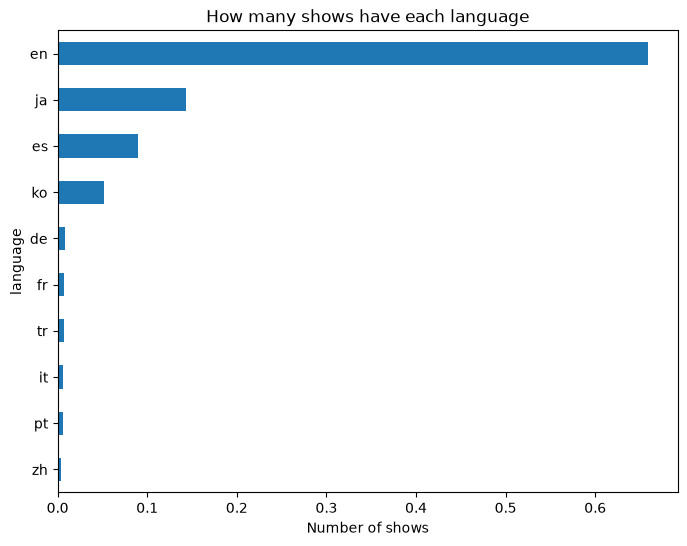

In [15]:
language_counts = (
    df["language"].value_counts(normalize=True).head(10)     # count how often each genre appears
)

language_counts.plot(kind="barh", figsize=(8, 6))   # horizontal bar chart (long names fit better)
plt.gca().invert_yaxis()                        # biggest bar at the top
plt.title("How many shows have each language")
plt.xlabel("Number of shows")
plt.show()

### Findings
**What I see**: 66% of shows are in English. Japanese (~14%, mostly anime), Spanish and Korean follow, and every other language is under 1%. There are no Nigerian-language shows.

**Why**: TMDB’s users are mostly English speakers, and I picked shows by vote count, so the catalogue reflects what TMDB users watch, not what the world watches.

**What it means for BingeBoard**: Anime fans are reasonably covered, but K-drama and C-drama fans, and Nigerian users looking for Nollywood, will find little. Possible fix: do extra fetches by language or country (TMDB’s discover page can filter by these) to fill the gaps.

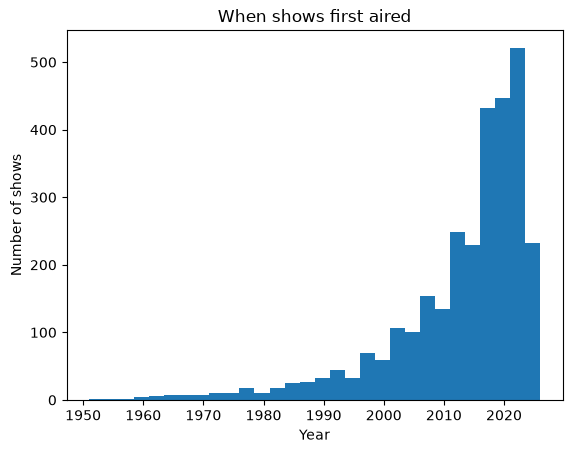

In [8]:
years = pd.to_datetime(df["first_aired"], errors="coerce").dt.year   # one year per show; bad dates become missing

years.plot(kind="hist", bins=30)        # the histogram groups years into 30 bins and counts them
plt.title("When shows first aired")
plt.xlabel("Year")
plt.ylabel("Number of shows")
plt.show()

### When shows first aired

**What I see:** Most shows are recent (roughly 70% first aired after 2010), peaking in
2020–2022. Shows before 2000 are a small share. The final bar (2024–2026) drops sharply.

**Why:** Streaming services have produced far more shows since ~2015. The drop at the end
is caused by how I built the catalogue: I sorted by vote count, and new shows haven't had
time to collect votes yet.

**What it means for BingeBoard:**
- Users who prefer classics will have a limited selection.
- "Today's picks" is meant to include new shows, but the catalogue barely has any.
  I need a separate fetch of recent shows (e.g. sorted by first air date).

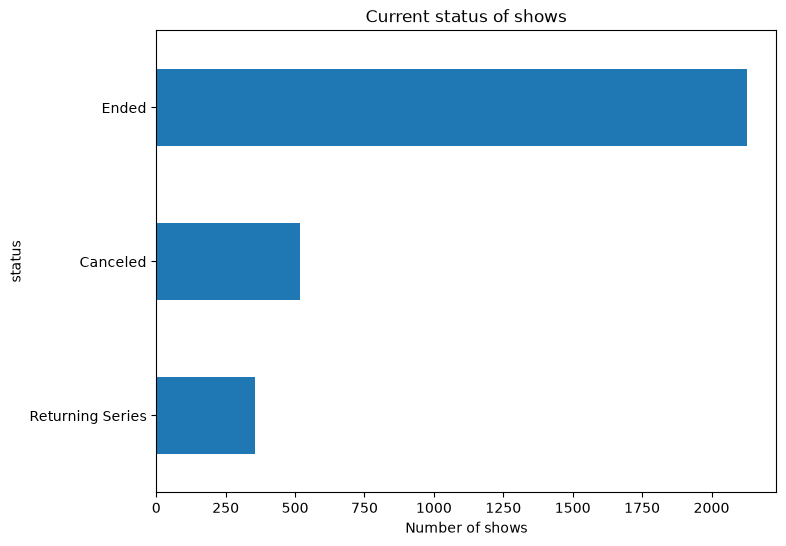

In [ ]:
status_counts = (
    df["status"].value_counts().head(10)     
)

status_counts.plot(kind="barh", figsize=(8, 6))   # horizontal bar chart (long names fit better)
plt.gca().invert_yaxis()                        # biggest bar at the top
plt.title("Current status of shows")
plt.xlabel("Number of shows")
plt.show()

### Current status of shows

**What I see:** ~71% of shows have Ended, ~17% were Cancelled, and only ~12% are still
running (Returning Series).

**Why:** Same cause as the year chart: older, finished shows have had years to collect
votes, so they dominate a catalogue sorted by vote count.

**What it means for BingeBoard:**
- Most recommendations will be complete stories, which suits binge-watchers.
- Cancelled shows may end on a cliffhanger, so the show page should show a "Cancelled" label.
- Users who want an ongoing show to follow weekly will find few options, which the
  recent-shows fetch would also help with.

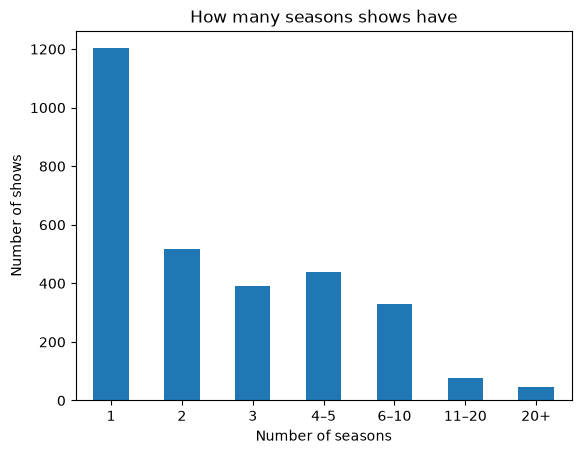

In [14]:
# Choose the bin edges yourself: detail at the low end, one bucket for long-runners
(df["seasons"] == 0).sum()
edges  = [0, 1, 2, 3, 5, 10, 20, 100]                       # 100 is just "bigger than any show"
labels = ["1", "2", "3", "4–5", "6–10", "11–20", "20+"]      # one label per bin (always one fewer than edges)

season_groups = pd.cut(df["seasons"], bins=edges, labels=labels)   # put each show in its bin
counts = season_groups.value_counts().sort_index()                 # count per bin, in bin order

counts.plot(kind="bar")
plt.title("How many seasons shows have")
plt.xlabel("Number of seasons")
plt.ylabel("Number of shows")
plt.xticks(rotation=0)   # keep labels horizontal
plt.show()

### Number of seasons

**What I see:** ~40% of shows have only 1 season. Most of the rest have 2–5, and
fewer than 5% run past 10 seasons.

**Why:** 1-season shows include limited series, K-dramas (usually planned as one season),
some anime (TMDB often lists it as one long season) and shows cancelled early.

**What it means for BingeBoard:**
- Shows vary hugely in time commitment, from one weekend to years of viewing.
- That could become a sign-up question or filter ("quick watch" vs "long commitment"),
  and a ranking signal for users who mostly finish short shows.
  

In [16]:
# Find shows whose keywords mention romance or love (case doesn't matter)
romance = df[df["keywords"].str.contains("romance|love", case=False, na=False)]
# str.contains → True if the text includes "romance" OR ("|") "love"
# na=False     → treat blank keywords as "no match" instead of crashing

print(len(romance))                     # how many shows match
print(romance["name"].head(20))         # eyeball them: do they look like romance shows?

431
3                  TONIKAWA: Over the Moon for You
9                             Moriarty the Patriot
10                                      Summertime
22                               Never Have I Ever
23                                        Love 101
33     Our Last Crusade or the Rise of a New World
34                               Too Hot to Handle
35          How a Realist Hero Rebuilt the Kingdom
47                                 Sweet Magnolias
48                              Bloque de búsqueda
52                                    All For Love
53             The Hidden Dungeon Only I Can Enter
58                               World's End Harem
87                              Love Is in the Air
88                                Sex and the City
89                                 Tokyo Revengers
90                                      Doña bella
97                                      True Blood
98                DON'T TOY WITH ME, MISS NAGATORO
103                        

In [17]:
# Split each show's keywords into separate items, one row per keyword
kw = romance["keywords"].str.split("|").explode()

# Keep only keywords containing "love" or "romance", and count them
matched = kw[kw.str.contains("romance|love", case=False)]
print(matched.value_counts().head(25))   # the 25 most common matching keywords

keywords
romance                   299
love                       42
bromance                   41
love triangle              41
first love                 20
teenage romance            19
unrequited love            14
interspecies romance       13
love polygon               13
boys' love (bl)             9
high school romance         8
forbidden love              8
loss of loved one           7
enemies to lovers           6
slow burn romance           6
love affair                 6
office romance              5
love at first sight         5
love-hate relationship      5
friends in love             5
friends to lovers           5
star crossed lovers         5
searching for love          3
gay romance                 3
lovecraftian                3
Name: count, dtype: int64


In [18]:
# Your hand-picked romance keywords (edit after looking at the list above)
ROMANCE_KEYWORDS = {"romance", "love", "romantic comedy", "first love", "love triangle", "gay romance", "slow burn romance", "star crossed lovers", "friends to lovers",
                    "friends in love", "love at first sight", "office romance", "love affair", "enemies to lovers", "high school romance", "forbidden love"}   # a set: fast "is it in here?" checks

def is_romance(keywords):
    """True if any of the show's keywords is exactly one of the romance keywords."""
    if not isinstance(keywords, str):      # blank/missing keywords → not romance
        return False
    return any(k.lower() in ROMANCE_KEYWORDS for k in keywords.split("|"))

romance = df[df["keywords"].apply(is_romance)]   # run is_romance on every show
print(len(romance))
print(romance["name"].sample(20, random_state=1))  # a random 20, not just the top, for a fairer check

358
2359                            Tomorrow is forever
2084                            Scarlet Heart: Ryeo
2830                              Extraordinary You
1574                                  Gilmore Girls
2719                                     Love Alarm
2423                                   Devils' Line
1951                                          Merlí
581                         See You in My 19th Life
2176                          Strong Girl Bong-soon
2538                                 Emily in Paris
1164                                    School Days
1034                                        56 Days
1199                                 Heated Rivalry
1657                                      The Heirs
2036                                 Maria Mercedes
1777                            Witches of East End
33      Our Last Crusade or the Rise of a New World
2369                          DARLING in the FRANXX
58                                World's End Harem
2829    